# EDA 02. Rain, Vegetation and Climate vs the Target

CRISP-DM phase: Data understanding

This notebook checks which rain, vegetation and ocean features go up or down before a flood, and whether that is a real signal or just the rainy season. Only the training rows (July 2002 to December 2019) are used.

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [51]:
#necessary imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

### 1.2 Loading the Dataset

In [52]:
#loading the full model table (pcode is kept as text)
df = pd.read_csv('../../data/private/model_table_full.csv', dtype={'pcode': str})

In [53]:
#keeping the training rows: July 2002 to December 2019
df['year_month'] = df['year'] * 100 + df['month']
train = df[(df['year_month'] >= 200207) & (df['year_month'] <= 201912)].copy()
train.shape

(9870, 71)

In [54]:
#target: 1 if the county has a flood in the following month
train['flood_next_month'].value_counts()

flood_next_month
0.0    8988
1.0     882
Name: count, dtype: int64

In [55]:
#the features checked in this notebook
rain_features = ['rain_mm', 'rain_max_dekad', 'rain_lag1', 'rain_lag2', 'rain_3mo_total', 'rain_pct_normal', 'neighbour_rain', 'neighbour_rain_lag1']
ndvi_features = ['ndvi', 'ndvi_pct_normal']
oni_features = ['oni', 'oni_lag1', 'oni_lag2', 'oni_lag3']
dmi_features = ['dmi', 'dmi_lag1', 'dmi_lag2', 'dmi_lag3']
calendar_features = ['month_sin', 'month_cos']
features = rain_features + ndvi_features + oni_features + dmi_features + calendar_features
len(features)

20

#### Observation

The training set has 9,870 rows: 8,988 are not followed by a flood and 882 are (8.9%). We check 20 features: 8 rain, 2 vegetation (NDVI), 4 ONI, 4 DMI and 2 calendar features.

## 2. Flood Rate by Fifth

Each feature is cut into 5 groups of the same size: Q1 is the lowest fifth and Q5 the highest. Then we calculate the share of rows in each group that are followed by a flood. If the flood rate goes steadily up or down from Q1 to Q5, the feature carries a signal.

`.rank(method='first')` is used before `pd.qcut` because many rows share the same value (for example 0 mm of rain), and ranking lets `qcut` make 5 groups of exactly the same size.

In [56]:
#flood rate (%) in each fifth, for every feature
rate_by_fifth = {}
for f in features:
    fifth = pd.qcut(train[f].rank(method='first'), 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
    rate_by_fifth[f] = train.groupby(fifth, observed=True)['flood_next_month'].mean() * 100
rate_by_fifth = pd.DataFrame(rate_by_fifth).T.round(1)
rate_by_fifth

,Q1,Q2,Q3,Q4,Q5
rain_mm,4.9,6.1,8.9,10.9,13.8
rain_max_dekad,4.7,6.3,8.8,10.9,14.0
rain_lag1,10.2,9.5,9.3,9.0,6.7
rain_lag2,13.7,9.8,9.0,7.0,5.1
rain_3mo_total,8.7,9.9,7.9,10.5,7.8
rain_pct_normal,5.7,5.6,6.7,10.6,16.1
neighbour_rain,4.5,4.8,8.5,12.1,14.8
neighbour_rain_lag1,9.6,9.6,8.9,8.8,7.8
ndvi,10.7,10.3,9.4,9.0,5.3
ndvi_pct_normal,7.0,7.2,5.4,8.8,16.3


#### Observation

The flood rate rises with the rain of the current month: `rain_pct_normal` goes from 5.7% in Q1 to 16.1% in Q5, `neighbour_rain` from 4.5% to 14.8% and `rain_mm` from 4.9% to 13.8%. It falls with the rain of earlier months: `rain_lag2` goes from 13.7% to 5.1% and `rain_lag1` from 10.2% to 6.7%. `rain_3mo_total` has no trend (8.7%, 9.9%, 7.9%, 10.5%, 7.8%). Greener-than-normal land goes with floods (`ndvi_pct_normal` is 16.3% in Q5), and so does a positive DMI (3.3% in Q1 against 12.5% in Q5). ONI is U-shaped (9.2%, 10.2%, 5.6%, 5.9%, 13.7%), so floods follow both ends of it.

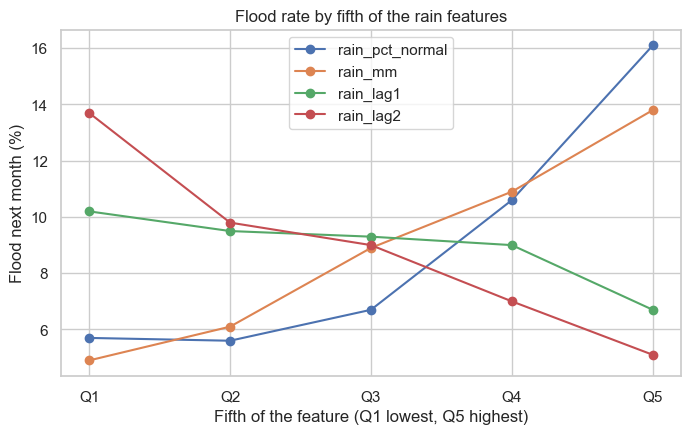

In [57]:
#flood rate by fifth for four rain features
plt.figure(figsize=(8, 4.5))
plt.plot(rate_by_fifth.columns, rate_by_fifth.loc['rain_pct_normal'], marker='o', label='rain_pct_normal')
plt.plot(rate_by_fifth.columns, rate_by_fifth.loc['rain_mm'], marker='o', label='rain_mm')
plt.plot(rate_by_fifth.columns, rate_by_fifth.loc['rain_lag1'], marker='o', label='rain_lag1')
plt.plot(rate_by_fifth.columns, rate_by_fifth.loc['rain_lag2'], marker='o', label='rain_lag2')
plt.xlabel('Fifth of the feature (Q1 lowest, Q5 highest)')
plt.ylabel('Flood next month (%)')
plt.title('Flood rate by fifth of the rain features')
plt.legend()
plt.show()

#### Observation

The lines rise for `rain_pct_normal` (the steepest) and `rain_mm`, and fall for `rain_lag1` and `rain_lag2`. A flood next month comes with more rain than usual now and less rain than usual one or two months before, so floods follow rain that rises quickly.

## 3. Is It Just the Season?

Floods happen mostly in the two rainy seasons, and rain is also highest then. So "more rain" could partly just mean "it is the rainy season", which the calendar already tells us.

To check this we use the **AUC**. Take one random row followed by a flood and one random row that is not, and guess that the flood row is the one with the higher value of the feature. The AUC is how often that guess is right:
- 0.5 means a coin flip, so the feature tells us nothing
- above 0.5 means higher values go with floods
- below 0.5 means lower values go with floods (0.40 is as useful as 0.60)

We calculate the AUC on all training rows and then inside each calendar month (and take the average of the 12 months). Inside one month every row comes from the same time of year, so the season can no longer help. If a feature's AUC stays away from 0.5 inside months, its signal is real. If it moves to 0.5, the signal was mostly the season.

In [58]:
#flood rate in each season
train.groupby('season')['flood_next_month'].mean().round(3)

season
JF      0.053
JJAS    0.045
MAM     0.141
OND     0.122
Name: flood_next_month, dtype: float64

In [59]:
#auc of each feature on all rows and inside months
auc_all = {}
auc_months = {}
for f in features:
    auc_all[f] = roc_auc_score(train['flood_next_month'], train[f])
    month_scores = []
    for m in range(1, 13):
        part = train[train['month'] == m]
        month_scores.append(roc_auc_score(part['flood_next_month'], part[f]))
    auc_months[f] = np.mean(month_scores)
auc_table = pd.DataFrame({'all rows': auc_all, 'inside months': auc_months}).round(3)
auc_table

,all rows,inside months
rain_mm,0.615,0.546
rain_max_dekad,0.617,0.540
rain_lag1,0.462,0.490
rain_lag2,0.395,0.470
rain_3mo_total,0.495,0.506
rain_pct_normal,0.630,0.626
neighbour_rain,0.646,0.583
neighbour_rain_lag1,0.476,0.517
ndvi,0.434,0.446
ndvi_pct_normal,0.604,0.618


#### Observation

The flood rate is 14.1% in MAM and 12.2% in OND, against 5.3% in JF and 4.5% in JJAS, so the season alone already says a lot. Inside months, `rain_pct_normal` (0.626), `ndvi_pct_normal` (0.618) and `dmi` (0.648) keep their signal, so they add real information beyond the season. `rain_mm` drops from 0.615 to 0.546 and `neighbour_rain` from 0.646 to 0.583, so part of their signal was the season, but some is left. `rain_lag2` moves from 0.395 to 0.470: weaker, but still on the same side. ONI drops to 0.478 to 0.514, so its signal was mostly the season. `month_sin` and `month_cos` are exactly 0.500 inside months, because they have the same value for every row in a month: all of their signal is the season, which is what they are for.

## 4. Ocean Climate: ONI and DMI

ONI measures El Nino (warm Pacific) and La Nina (cold Pacific), and DMI measures the Indian Ocean Dipole. We use the usual thresholds: ONI of +0.5 or more is El Nino and -0.5 or less is La Nina; DMI of +0.4 or more is positive and -0.4 or less is negative.

Both indices are the same for all 47 counties, so each month is repeated 47 times. The real number of cases is the number of months, not the number of rows.

In [60]:
#ONI phase of each row
train['oni_phase'] = 'neutral'
train.loc[train['oni'] >= 0.5, 'oni_phase'] = 'El Nino'
train.loc[train['oni'] <= -0.5, 'oni_phase'] = 'La Nina'

#DMI phase of each row
train['dmi_phase'] = 'neutral'
train.loc[train['dmi'] >= 0.4, 'dmi_phase'] = 'positive'
train.loc[train['dmi'] <= -0.4, 'dmi_phase'] = 'negative'

In [61]:
#number of months in each phase (one row per month)
months = train.drop_duplicates(['year', 'month'])
print(months['oni_phase'].value_counts())
print(months['dmi_phase'].value_counts())

oni_phase
neutral    101
El Nino     59
La Nina     50
Name: count, dtype: int64
dmi_phase
neutral     154
positive     34
negative     22
Name: count, dtype: int64


In [62]:
#flood rate (%) by ONI phase, for all rows and inside each season
oni_rates = train.groupby(['oni_phase', 'season'])['flood_next_month'].mean().unstack() * 100
oni_rates['all rows'] = train.groupby('oni_phase')['flood_next_month'].mean() * 100
oni_rates.round(1)

season,JF,JJAS,MAM,OND,all rows
oni_phase,,,,,
El Nino,4.1,4.3,15.4,17.8,11.5
La Nina,7.4,7.1,13.3,10.9,10.0
neutral,4.3,4.1,13.8,6.5,6.9


In [63]:
#flood rate (%) by DMI phase, for all rows and inside each season
dmi_rates = train.groupby(['dmi_phase', 'season'])['flood_next_month'].mean().unstack() * 100
dmi_rates['all rows'] = train.groupby('dmi_phase')['flood_next_month'].mean() * 100
dmi_rates.round(1)

season,JF,JJAS,MAM,OND,all rows
dmi_phase,,,,,
negative,1.1,0.2,9.1,2.7,3.6
neutral,5.6,3.7,14.7,11.5,8.8
positive,NaN,8.6,16.0,18.9,13.0


#### Observation

The training years have 210 months: 59 El Nino, 50 La Nina and 101 neutral by ONI, and only 34 positive and 22 negative by DMI. DMI is in a clean order: 13.0% of positive DMI rows are followed by a flood, 8.8% of neutral rows and 3.6% of negative rows, and the same order holds in JJAS, MAM and OND (there were no positive DMI months in JF). ONI is less clear: El Nino gives the highest rate in OND (17.8% against 6.5% for neutral), but in JF and JJAS La Nina is the highest. Because these results come from a few dozen months, they are weaker evidence than the rain results.

## 5. Verdict for Each Feature

The table puts the main numbers together. Q1 to Q5 is the flood rate in the lowest and highest fifth, and the AUC is on all rows and inside months. The final choice is made in `04_feature_overlap_and_selection`, after checking which features repeat each other.

| feature | Q1 to Q5 (%) | AUC all rows | AUC inside months | verdict | reason |
|---|---|---|---|---|---|
| `rain_pct_normal` | 5.7 to 16.1 | 0.630 | 0.626 | keep | the best rain signal, and it is not just the season |
| `rain_mm` | 4.9 to 13.8 | 0.615 | 0.546 | keep | rain of the month, part of its signal is the season |
| `rain_max_dekad` | 4.7 to 14.0 | 0.617 | 0.540 | maybe drop | almost the same as `rain_mm` |
| `rain_lag1` | 10.2 to 6.7 | 0.462 | 0.490 | keep (weak) | less rain before a flood: the rain is rising |
| `rain_lag2` | 13.7 to 5.1 | 0.395 | 0.470 | keep | the clearest "rain is rising" signal |
| `rain_3mo_total` | 8.7 to 7.8 | 0.495 | 0.506 | drop | no trend and no signal |
| `neighbour_rain` | 4.5 to 14.8 | 0.646 | 0.583 | keep | rain in the surrounding counties, highest overall AUC |
| `neighbour_rain_lag1` | 9.6 to 7.8 | 0.476 | 0.517 | maybe drop | close to 0.5 inside months |
| `ndvi` | 10.7 to 5.3 | 0.434 | 0.446 | maybe drop | probably tells us which county it is, not the weather |
| `ndvi_pct_normal` | 7.0 to 16.3 | 0.604 | 0.618 | keep | holds inside months |
| `oni`, `oni_lag1` to `oni_lag3` | U-shaped | 0.530 to 0.554 | 0.478 to 0.514 | maybe drop | no signal inside months, only about 210 months |
| `dmi` | 3.3 to 12.5 | 0.609 | 0.648 | keep | the best ocean feature, same order in every season |
| `dmi_lag1` | 4.5 to 13.8 | 0.593 | 0.593 | keep | still strong, overlap with `dmi` checked in 04 |
| `dmi_lag2`, `dmi_lag3` | 6.4 to 12.3, 4.8 to 10.5 | 0.562, 0.568 | 0.557, 0.548 | maybe drop | weaker versions of `dmi` |
| `month_sin`, `month_cos` | 8.5 to 16.5, 3.5 to 7.0 | 0.567, 0.555 | 0.500 | keep | give the model the time of year |

## 6. Summary

A flood next month goes with more rain than normal now (`rain_pct_normal`, `rain_mm`, `neighbour_rain`), less rain one or two months before (`rain_lag1`, `rain_lag2`), greener-than-normal land (`ndvi_pct_normal`) and a positive Indian Ocean Dipole (`dmi`). These signals stay after the season is controlled for, although `rain_mm` and `neighbour_rain` get weaker. `rain_3mo_total` and the ONI features add little once the season is known. The ocean results rest on about 210 months, so they are weaker evidence than the rain results. The next notebook, `04_feature_overlap_and_selection`, checks which of the kept features repeat each other and picks the final list.